# 02. Análisis exploratorio

Vamos a conocer cómo se comportan los sensores y los eventos antes de construir las etiquetas o entrenar modelos.

Revisaremos:

1. La distribución de los cuatro sensores por modelo de máquina.
2. La frecuencia de errores, mantenimientos y fallas por componente (los errores se agrupan por tipo porque no incluyen componente).
3. Las mediciones de las **72 horas anteriores a una falla**, comparadas con periodos sin fallas cercanas, incluyendo un resumen de las últimas 48 y 24 horas.

**Usaremos solo enero–agosto de 2015**, el periodo de entrenamiento. Septiembre–octubre y noviembre–diciembre no se usarán para explorar patrones. El margen de 24 horas para las etiquetas se aplicará en su propio paso; aquí todavía no hay etiquetas predictivas.


## 1. Herramientas, rutas y periodo de trabajo

Usaremos pandas y NumPy para las tablas, y Matplotlib y Seaborn para las gráficas. Las rutas se encuentran desde el repositorio o desde la carpeta `EDA`. Guardaremos cinco figuras en `EDA/Figuras` para facilitar su revisión; todavía no constituyen el reporte.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Obtener la carpeta desde la que se está ejecutando el notebook.
carpeta_actual = Path.cwd()

# Si Datos está aquí, ya estamos en la raíz del repositorio.
if (carpeta_actual / "Datos").is_dir():
    ruta_repo = carpeta_actual
    
# Si estamos en una subcarpeta del proyecto, buscar Datos un nivel arriba.
elif (carpeta_actual.parent / "Datos").is_dir():
    ruta_repo = carpeta_actual.parent
else:
    raise FileNotFoundError("Ejecuta el notebook desde el repositorio o la carpeta EDA.")

# Construir la ruta de los CSV sin imprimir rutas personales.
ruta_datos = ruta_repo / "Datos"
ruta_figuras = ruta_repo / "EDA" / "Figuras"

# Crear la carpeta de figuras si aún no existe; parents permite crear carpetas superiores necesarias.
ruta_figuras.mkdir(parents=True, exist_ok=True)

# Fijar los límites temporales antes de resumir o graficar los datos.
inicio = pd.Timestamp("2015-01-01 00:00:00")
fin = pd.Timestamp("2015-09-01 00:00:00")  # Límite excluido: no usar septiembre.

# Estos son los nombres originales de las cuatro columnas de mediciones.
sensores = ["volt", "rotate", "pressure", "vibration"]

# Usar nombres legibles en las gráficas sin renombrar las columnas del archivo.
nombres_sensores = {
    "volt": "Voltaje", "rotate": "Rotación",
    "pressure": "Presión", "vibration": "Vibración",
}
# Fijar un orden común para que las tablas y gráficas sean fáciles de comparar.
modelos = ["model1", "model2", "model3", "model4"]
componentes = ["comp1", "comp2", "comp3", "comp4"]

# Configurar la apariencia de las figuras; no afecta los cálculos.
sns.set_theme(style="whitegrid", context="notebook")

# Estas opciones solo cambian cómo se muestran las tablas, no sus valores.
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 25)

No utilizaremos muestreo aleatorio: los conteos usan todos los registros de entrenamiento y la selección de periodos de comparación será determinista.

## 2. Leer y separar los datos de entrenamiento

Leemos los cinco CSV y filtramos las tablas con fecha antes de calcular resúmenes o gráficas. El catálogo de máquinas contiene información estática.

Los mantenimientos de 2014 se conservan en el CSV original, pero no se suman a las frecuencias de enero–agosto. Su utilidad como historia previa se revisará en el siguiente paso de preprocesamiento.

In [2]:
# Relacionar un nombre corto con el nombre real de cada archivo CSV.
archivos = {
    "telemetria": "PdM_telemetry.csv",
    "errores": "PdM_errors.csv",
    "mantenimiento": "PdM_maint.csv",
    "fallas": "PdM_failures.csv",
}

# Guardar únicamente las tablas filtradas al periodo de entrenamiento.
datos = {}
resumen = []

# Recorrer el diccionario: nombre es la etiqueta y archivo es el CSV correspondiente.
for nombre, archivo in archivos.items():
    
    # Leer el archivo y convertir datetime a fecha desde la carga.
    tabla = pd.read_csv(ruta_datos / archivo, parse_dates=["datetime"])
    
    # Combinar condiciones con &: incluir enero y excluir septiembre y todo lo posterior.
    seleccion = (tabla["datetime"] >= inicio) & (tabla["datetime"] < fin)
    
    # loc selecciona filas; copy permite trabajar con ellas de forma independiente.
    datos[nombre] = tabla.loc[seleccion].copy()
    
    # Registrar cuántas filas conservamos y sus fechas para comprobar el filtro.
    resumen.append({
        "tabla": nombre,
        "registros_entrenamiento": len(datos[nombre]),
        "primera_fecha": datos[nombre]["datetime"].min(),
        "ultima_fecha": datos[nombre]["datetime"].max(),
    })
    
    # No conservar las observaciones de validación o prueba en las tablas de trabajo.
    del tabla

# Leer el catálogo estático para añadir modelo y antigüedad a cada medición.
maquinas = pd.read_csv(ruta_datos / "PdM_machines.csv")

# Cruzar por machineID: conservar todas las mediciones y exigir una sola fila de catálogo por máquina.
telemetria = datos["telemetria"].merge(maquinas, on="machineID", how="left", validate="many_to_one")
errores = datos["errores"]
mantenimiento = datos["mantenimiento"]
fallas = datos["fallas"]

# Liberar el diccionario auxiliar; las tablas con nombres propios siguen disponibles.
del datos

# Comprobar que ninguna tabla de trabajo contiene fechas fuera de entrenamiento.
for tabla in [telemetria, errores, mantenimiento, fallas]:
    assert tabla["datetime"].between(inicio, fin, inclusive="left").all()
    
# assert detiene la ejecución si una medición no encontró su modelo en el catálogo.
assert not telemetria["model"].isna().any()
display(pd.DataFrame(resumen))

# Contar máquinas por modelo, no filas de telemetría.
display(maquinas.groupby("model").size().reindex(modelos).rename("máquinas").to_frame())

,tabla,registros_entrenamiento,primera_fecha,ultima_fecha
0,telemetria,582600,2015-01-01 06:00:00,2015-08-31 23:00:00
1,errores,2611,2015-01-01 06:00:00,2015-08-31 21:00:00
2,mantenimiento,1916,2015-01-01 06:00:00,2015-08-31 06:00:00
3,fallas,522,2015-01-02 03:00:00,2015-08-31 06:00:00


,máquinas
model,
model1,16
model2,17
model3,35
model4,32


Trabajaremos con **582,600 horas-máquina, 2,611 errores, 1,916 registros de mantenimiento y 522 registros de falla**, todos entre enero y agosto. Hay 16 máquinas `model1`, 17 `model2`, 35 `model3` y 32 `model4`.

Los modelos no tienen el mismo número de máquinas; por eso no conviene interpretar diferencias de conteos absolutos como diferencias de riesgo. Esta revisión no necesita información de validación ni de prueba.

## 3. Distribución de sensores por modelo

Primero mostraremos mediana, promedio, desviación estándar y cuartiles de cada sensor por modelo. Luego compararemos sus distribuciones con diagramas de caja, sin mezclar las escalas de los cuatro sensores.

La línea dentro de cada caja es la mediana y la caja contiene la mitad central de las mediciones. Los puntos más allá de los bigotes se ocultan para que la figura sea legible; **no se eliminan datos de los cálculos**. Los CSV no detallan las unidades físicas, así que no inventaremos unidades.

Voltaje


,count,mean,std,min,median,max
model,,,,,,
model1,93216,170.75,15.56,97.33,170.58,248.48
model2,99042,170.91,15.64,98.34,170.66,250.87
model3,203910,170.86,15.48,100.19,170.71,247.06
model4,186432,170.73,15.45,103.53,170.54,243.93


Rotación


,count,mean,std,min,median,max
model,,,,,,
model1,93216,446.69,52.83,176.92,447.60,659.03
model2,99042,446.44,52.72,177.24,447.43,670.72
model3,203910,446.51,52.67,173.63,447.53,655.70
model4,186432,446.67,52.48,167.10,447.63,681.04


Presión


,count,mean,std,min,median,max
model,,,,,,
model1,93216,101.21,11.48,56.73,100.61,185.95
model2,99042,101.14,11.33,57.40,100.59,170.86
model3,203910,100.63,10.81,51.25,100.30,177.03
model4,186432,100.63,10.81,54.17,100.29,174.79


Vibración


,count,mean,std,min,median,max
model,,,,,,
model1,93216,40.44,5.40,19.24,40.30,70.59
model2,99042,40.38,5.36,20.01,40.21,70.30
model3,203910,40.42,5.36,16.22,40.27,76.79
model4,186432,40.34,5.35,14.88,40.20,71.95


volt  rotate  pressure  vibration
model                                           
model1 0.25  160.20  412.21     93.63      36.80
       0.75  181.04  482.39    107.85      43.85
model2 0.25  160.34  412.37     93.54      36.76
       0.75  181.24  481.89    107.84      43.80
model3 0.25  160.41  412.19     93.42      36.82
       0.75  181.04  482.13    107.34      43.81
model4 0.25  160.32  412.34     93.43      36.76
       0.75  180.94  482.15    107.34      43.75

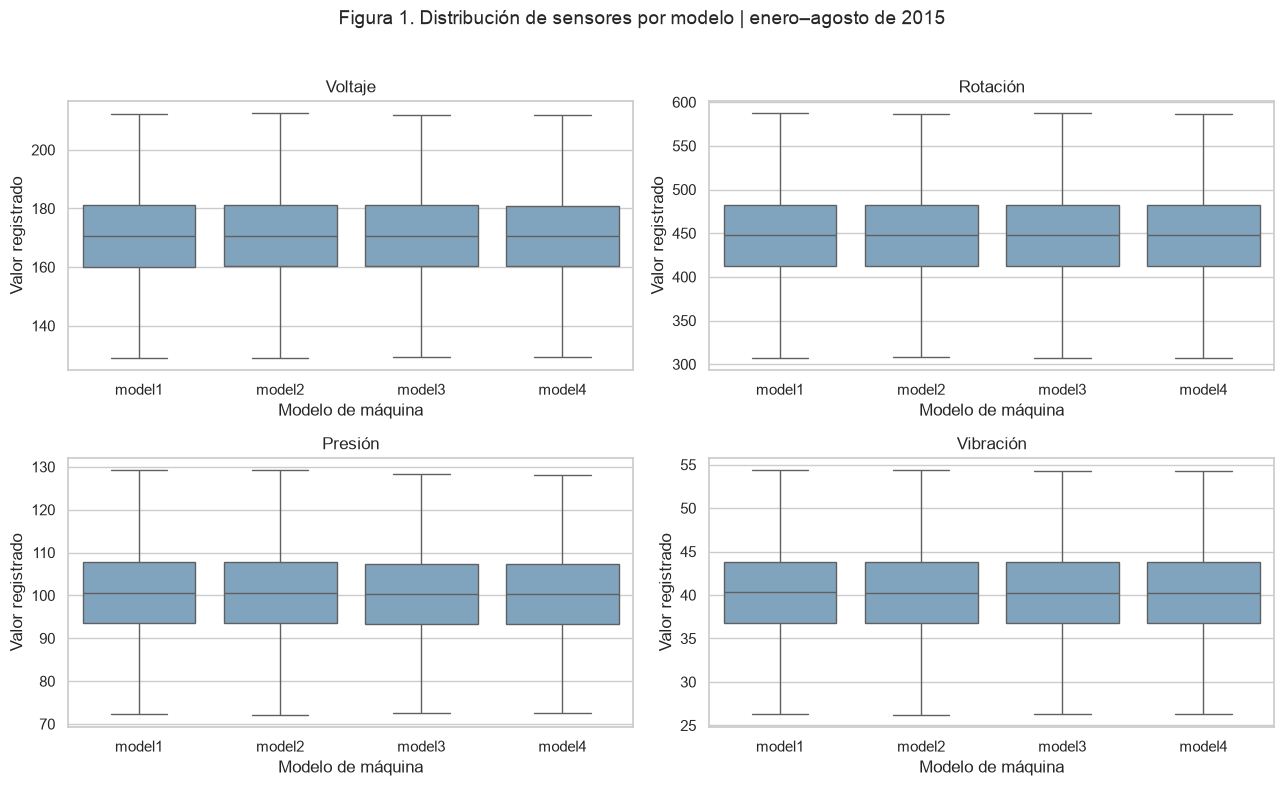

In [3]:
# Agrupar por modelo y calcular cantidad, media, dispersión, extremos y mediana de cada sensor.
resumen_sensores = telemetria.groupby("model")[sensores].agg(
    ["count", "mean", "std", "min", "median", "max"]
).reindex(modelos)

# Recorrer los sensores para mostrar cada resumen por separado.
for sensor in sensores:
    print(nombres_sensores[sensor])
    display(resumen_sensores[sensor].round(2))

# Los cuantiles 0.25 y 0.75 delimitan la mitad central de las mediciones.
cuartiles = telemetria.groupby("model")[sensores].quantile([0.25, 0.75])
display(cuartiles.round(2))

# Crear varios paneles para comparar sin mezclar las escalas de los sensores.
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

# zip empareja cada sensor con un panel; flat recorre los paneles de la cuadrícula.
for sensor, eje in zip(sensores, ejes.flat):
    
    # Dibujar cajas por modelo; showfliers=False oculta puntos extremos en la figura, sin borrarlos.
    sns.boxplot(data=telemetria, x="model", y=sensor, order=modelos,
                showfliers=False, color="#77a6c8", ax=eje)
    eje.set_title(nombres_sensores[sensor])
    eje.set_xlabel("Modelo de máquina")
    eje.set_ylabel("Valor registrado")
fig.suptitle("Figura 1. Distribución de sensores por modelo | enero–agosto de 2015", fontsize=14)

# Ajustar los espacios para evitar que los títulos y etiquetas se encimen.
fig.tight_layout(rect=(0, 0, 1, 0.96))

# Guardar una copia de la figura; no modifica los datos originales.
fig.savefig(ruta_figuras / "01_sensores_por_modelo.png", dpi=160, bbox_inches="tight")

# Mostrar la figura en la salida del notebook.
plt.show()

Las cajas de los cuatro modelos son muy parecidas: sus valores centrales y su dispersión se superponen ampliamente. Por ejemplo, la mediana de voltaje se encuentra alrededor de 170.5–170.7 y la de vibración alrededor de 40.2–40.3.

La distribución general no muestra una separación marcada por modelo. Eso **no demuestra que el modelo de máquina sea irrelevante** ni decide la normalización que usaremos después. Además, una señal cercana a fallas puede quedar oculta al mezclar todas las horas, porque esos periodos son una parte pequeña del total.

## 4. Frecuencia de errores, mantenimientos y fallas

Los errores solo tienen `errorID`, de modo que los contamos por tipo. Los mantenimientos y las fallas sí se pueden contar por componente. Cada fila es un registro de evento; si varios componentes fallan en la misma hora, cada uno conserva su registro.

No debemos sumar mantenimiento y fallas como si fueran sucesos independientes: algunos reemplazos pueden ser consecuencia de fallas. La coincidencia entre ambos archivos se estudiará en el paso 3.

,registros_error
errorID,
error1,688
error2,647
error3,564
error4,471
error5,241


,registros_mantenimiento,registros_falla
comp1,464,141
comp2,510,168
comp3,469,91
comp4,473,122


Registros de falla: 522
Horas-máquina con al menos una falla: 493


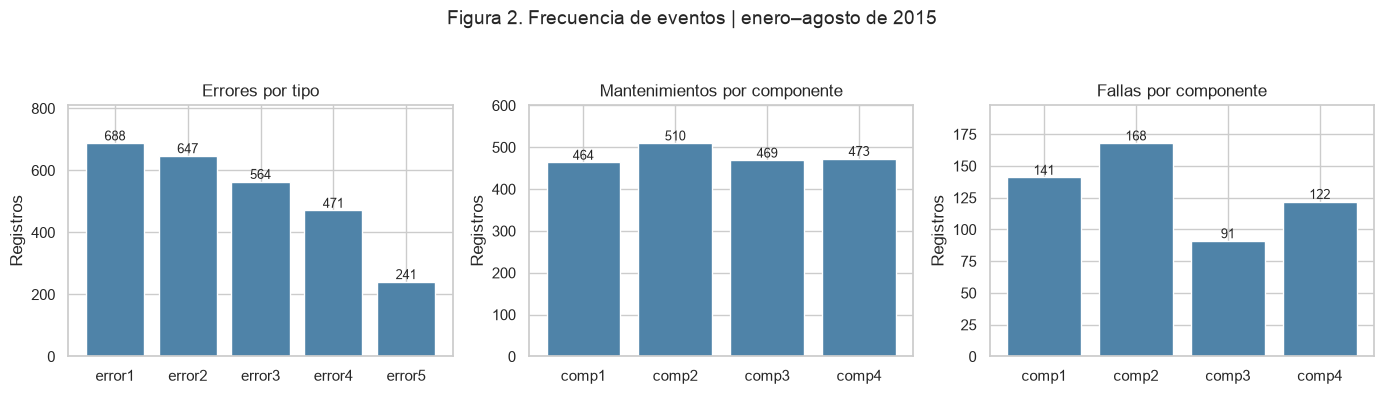

In [4]:
# value_counts cuenta cada tipo; reindex conserva el orden y muestra cero si falta alguna categoría.
conteo_errores = errores["errorID"].value_counts().reindex(
    ["error1", "error2", "error3", "error4", "error5"], fill_value=0
)

# Contar cada componente reemplazado, conservando todos los registros de mantenimiento.
conteo_mantenimiento = mantenimiento["comp"].value_counts().reindex(componentes, fill_value=0)

# Contar fallas por componente; varios componentes pueden compartir máquina y hora.
conteo_fallas = fallas["failure"].value_counts().reindex(componentes, fill_value=0)

display(conteo_errores.rename("registros_error").to_frame())
tabla_componentes = pd.DataFrame({
    "registros_mantenimiento": conteo_mantenimiento,
    "registros_falla": conteo_fallas,
})
display(tabla_componentes)
print("Registros de falla:", len(fallas))

# Quitar coincidencias de máquina y hora solo para este conteo de episodios, sin cambiar la tabla original.
print("Horas-máquina con al menos una falla:", len(fallas.drop_duplicates(["machineID", "datetime"])))

# Crear varios paneles para comparar sin mezclar las escalas de los sensores.
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
conteos = [conteo_errores, conteo_mantenimiento, conteo_fallas]
titulos = ["Errores por tipo", "Mantenimientos por componente", "Fallas por componente"]

# Emparejar los conteos, los títulos y los tres paneles en el mismo orden.
for conteo, titulo, eje in zip(conteos, titulos, ejes):
    eje.bar(conteo.index, conteo.values, color="#4f83a8")
    eje.set_title(titulo)
    eje.set_ylabel("Registros")
    
    # enumerate aporta la posición de cada barra para escribir su conteo encima.
    for posicion, valor in enumerate(conteo.values):
        eje.text(posicion, valor, str(valor), ha="center", va="bottom", fontsize=9)
    eje.margins(y=0.18)
fig.suptitle("Figura 2. Frecuencia de eventos | enero–agosto de 2015", fontsize=14)

# Ajustar los espacios para evitar que los títulos y etiquetas se encimen.
fig.tight_layout(rect=(0, 0, 1, 0.93))

# Guardar una copia de la figura; no modifica los datos originales.
fig.savefig(ruta_figuras / "02_frecuencia_eventos.png", dpi=160, bbox_inches="tight")

# Mostrar la figura en la salida del notebook.
plt.show()

`error1` es el error más frecuente (**688 registros**) y `error5` el menos frecuente (**241**). El componente con más fallas es `comp2` (**168**), seguido de `comp1` (**141**), `comp4` (**122**) y `comp3` (**91**).

Las **522 filas de fallas corresponden a 493 horas-máquina distintas**: algunas incluyen más de un componente. Estos conteos no son todavía el desbalance de etiquetas a 24 horas; una misma falla generará varias horas positivas cuando se construya esa etiqueta.

Hay más registros de mantenimiento que de falla para cada componente. El conteo por sí solo no permite determinar cuáles fueron programados y cuáles respondieron a una falla; eso se revisará al relacionar ambos archivos.

### Frecuencia por mes y tiempo observado

Los meses no tienen la misma duración y la telemetría de enero comienza a las 06:00. Por eso, además de los conteos, calcularemos registros por **10,000 horas-máquina observadas**. Una hora observada de una máquina equivale a una fila de telemetría.

Esta tasa es descriptiva: no representa la probabilidad de falla de las siguientes 24 horas.

,horas_maquina,errores,mantenimiento,fallas
2015-01,73800,356,196,94
2015-02,67200,291,204,50
2015-03,74400,351,238,59
2015-04,72000,326,238,69
2015-05,74400,314,267,64
2015-06,72000,315,253,58
2015-07,74400,299,268,64
2015-08,74400,359,252,64


,errores,mantenimiento,fallas
2015-01,48.24,26.56,12.74
2015-02,43.30,30.36,7.44
2015-03,47.18,31.99,7.93
2015-04,45.28,33.06,9.58
2015-05,42.20,35.89,8.60
2015-06,43.75,35.14,8.06
2015-07,40.19,36.02,8.60
2015-08,48.25,33.87,8.60


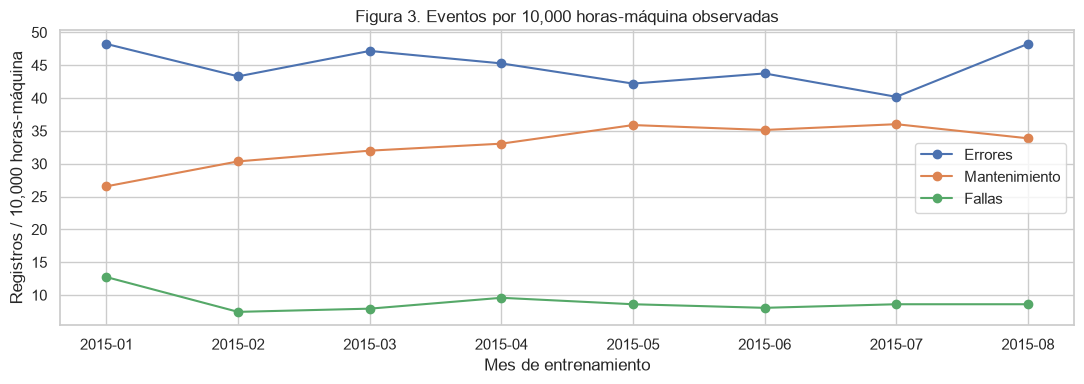

In [5]:
# Definir los ocho meses para que todas las series mensuales tengan el mismo índice.
meses = pd.period_range("2015-01", "2015-08", freq="M")

# Cada fila es una hora-máquina; agrupar por mes mide el tiempo observado de toda la flota.
horas_por_mes = telemetria.groupby(telemetria["datetime"].dt.to_period("M")).size().reindex(meses)
conteos_mensuales = pd.DataFrame(index=meses)
conteos_mensuales["horas_maquina"] = horas_por_mes

# Repetir el conteo mensual para errores, mantenimiento y fallas.
for nombre, tabla in [("errores", errores), ("mantenimiento", mantenimiento), ("fallas", fallas)]:
    conteos_mensuales[nombre] = tabla.groupby(tabla["datetime"].dt.to_period("M")).size().reindex(meses, fill_value=0)
display(conteos_mensuales)

# Dividir cada conteo entre las horas observadas de ese mes y expresarlo por 10,000 horas-máquina.
tasas = conteos_mensuales[["errores", "mantenimiento", "fallas"]].div(
    conteos_mensuales["horas_maquina"], axis=0
) * 10000
display(tasas.round(2))
fig, eje = plt.subplots(figsize=(11, 4))

# Trazar una línea por tipo de evento sobre los mismos meses.
for nombre in tasas.columns:
    eje.plot(meses.astype(str), tasas[nombre], marker="o", label=nombre.capitalize())
eje.set_title("Figura 3. Eventos por 10,000 horas-máquina observadas")
eje.set_xlabel("Mes de entrenamiento")
eje.set_ylabel("Registros / 10,000 horas-máquina")
eje.legend()

# Ajustar los espacios para evitar que los títulos y etiquetas se encimen.
fig.tight_layout()

# Guardar una copia de la figura; no modifica los datos originales.
fig.savefig(ruta_figuras / "03_eventos_mensuales.png", dpi=160, bbox_inches="tight")

# Mostrar la figura en la salida del notebook.
plt.show()

Enero registra la mayor tasa de fallas: **12.74 por 10,000 horas-máquina**, frente a valores entre **7.44 y 9.58** en los otros meses de entrenamiento. Las tasas de errores van aproximadamente de **40.19 a 48.25**.

Esto muestra variación mensual que conviene tener presente al comparar periodos. La gráfica no permite atribuir esa variación a desgaste, mantenimiento u otra causa; tampoco implica que exista una tendencia que vaya a repetirse.

## 5. Preparar la comparación antes de una falla

Compararemos ventanas de **72 mediciones**, desde 72 horas antes hasta una hora antes de la falla. La hora de la falla se excluye para no confundir una señal previa con lo que ocurre al fallar o al reemplazar el componente.

Para cada hora-máquina con falla:

1. Pedimos 72 horas completas de telemetría dentro de entrenamiento.
2. Excluimos ventanas que contengan otra falla de esa máquina entre −72 y −1 horas.
3. Buscamos una ventana de comparación de la **misma máquina y misma hora del día**, con el ancla más cercana en fecha.
4. El ancla sana debe tener 72 horas anteriores completas y otras 72 horas posteriores dentro de entrenamiento, sin fallas de ningún componente en todo ese intervalo, incluidos sus extremos.
5. No reutilizamos la misma ancla sana para una misma máquina. Si no hay comparación disponible, descartamos el par y lo contamos.

“Sano” significa **sin fallas registradas en ese intervalo**; puede haber errores o mantenimiento. Esta es una comparación retrospectiva para explorar los datos, no una etiqueta ni una regla que se pueda usar al predecir.

Una falla simultánea de varios componentes cuenta una sola vez en la comparación general. En el análisis por componente, esa ventana pertenece a cada componente afectado. Las ventanas de distintos pares pueden solaparse; por eso sus mediciones no deben tratarse como observaciones independientes.

In [6]:
# La ventana tendrá 72 mediciones anteriores al ancla, sin incluir la hora del evento.
horas_ventana = 72
una_hora = pd.Timedelta(hours=1)
duracion = pd.Timedelta(hours=horas_ventana)

# Un ancla es la hora de referencia: unir fallas simultáneas para no repetirlas en la comparación general.
anclas_falla = fallas[["machineID", "datetime"]].drop_duplicates().sort_values(["machineID", "datetime"])

# Indexar por máquina y hora permite recuperar exactamente las mediciones de cada ventana.
telemetria_indice = telemetria.set_index(["machineID", "datetime"]).sort_index()

# Guardar las fechas de falla de cada máquina para consultarlas sin mezclar máquinas.
fallas_por_maquina = {}

# Guardar las posibles horas de referencia sanas para cada máquina.
candidatos_por_maquina = {}

# Revisar una máquina a la vez para construir sus controles sanos.
for maquina_id, grupo in telemetria.groupby("machineID"):
    fechas_falla = pd.DatetimeIndex(
        anclas_falla.loc[anclas_falla["machineID"] == maquina_id, "datetime"].sort_values()
    )
    fallas_por_maquina[maquina_id] = fechas_falla
    horas_maquina = pd.DatetimeIndex(grupo["datetime"].sort_values())
    
    # Exigir historia previa completa y 72 horas posteriores dentro de entrenamiento.
    candidatos = horas_maquina[
        (horas_maquina >= horas_maquina.min() + duracion)
        & (horas_maquina + duracion < fin)
    ]
    
    # searchsorted cuenta fallas dentro del intervalo cerrado [ancla - 72h, ancla + 72h].
    # Buscar dónde empezaría el intervalo dentro de las fechas ordenadas de fallas.
    posiciones_inicio = fechas_falla.searchsorted(candidatos - duracion, side="left")
    
    # Buscar dónde terminaría; si ambas posiciones coinciden, no hay fallas en el intervalo.
    posiciones_fin = fechas_falla.searchsorted(candidatos + duracion, side="right")
    candidatos_por_maquina[maquina_id] = candidatos[posiciones_inicio == posiciones_fin]

pares = []
exclusiones = {"historia_incompleta": 0, "otra_falla_en_historia": 0, "sin_comparacion_sana": 0}

# Recordar las anclas sanas elegidas para no reutilizar una misma ancla de una máquina.
usadas = set()

# itertuples recorre cada fila permitiendo leer machineID y datetime por su nombre.
for evento in anclas_falla.itertuples(index=False):
    maquina_id = evento.machineID
    fecha_falla = evento.datetime
    
    # Construir las horas −72 a −1; periods fija la cantidad de registros solicitados.
    horas_previas = pd.date_range(fecha_falla - duracion, periods=horas_ventana, freq="h")
    
    # Combinar una máquina con todas sus horas para buscar esa ventana en el índice de telemetría.
    indice_ventana = pd.MultiIndex.from_product([[maquina_id], horas_previas])
    
    # Si falta una sola hora, contar la exclusión y saltar este evento con continue.
    if not indice_ventana.isin(telemetria_indice.index).all():
        exclusiones["historia_incompleta"] += 1
        continue
    fechas_falla = fallas_por_maquina[maquina_id]
    
    # Buscar otra falla anterior dentro de la ventana; excluir la falla del ancla actual.
    fallas_previas = fechas_falla[(fechas_falla >= fecha_falla - duracion) & (fechas_falla < fecha_falla)]
    if len(fallas_previas) > 0:
        exclusiones["otra_falla_en_historia"] += 1
        continue
    candidatos = candidatos_por_maquina[maquina_id]
    
    # Comparar a la misma hora del día para reducir diferencias relacionadas con horarios.
    candidatos = candidatos[candidatos.hour == fecha_falla.hour]
    
    # Conservar únicamente anclas que todavía no se han utilizado como control de esa máquina.
    candidatos = [fecha for fecha in candidatos if (maquina_id, fecha) not in usadas]
    
    # Si no hay control elegible, registrar el motivo sin inventar una ventana.
    if len(candidatos) == 0:
        exclusiones["sin_comparacion_sana"] += 1
        continue
    
    # En caso de empate, elegir la fecha anterior: selección determinista.
    
    # Elegir la menor distancia de fechas; la segunda clave resuelve los empates por fecha anterior.
    fecha_sana = min(candidatos, key=lambda fecha: (abs(fecha - fecha_falla), fecha))
    usadas.add((maquina_id, fecha_sana))
    
    # Guardar el vínculo entre la falla y su control con un identificador de par.
    pares.append({"par": len(pares), "machineID": maquina_id,
                  "fecha_falla": fecha_falla, "fecha_sana": fecha_sana})

pares = pd.DataFrame(pares)
if pares.empty:
    raise ValueError("No se encontraron pares completos; revisar los criterios.")

# Comprobar que todos los episodios quedaron incluidos o tienen un motivo de exclusión.
assert len(pares) + sum(exclusiones.values()) == len(anclas_falla)

# Quitar coincidencias de máquina y hora solo para este conteo de episodios, sin cambiar la tabla original.
print("Horas-máquina con falla disponibles:", len(anclas_falla))
print("Pares conservados:", len(pares))
print("Exclusiones:", exclusiones)
display(pares.head(8))

# Cada par aporta exactamente 72 horas en cada grupo.
ventanas = []

# Recuperar las dos ventanas de cada par: antes de falla y sana comparable.
for par in pares.itertuples(index=False):
    for grupo, ancla in [("Antes de falla", par.fecha_falla), ("Sano comparable", par.fecha_sana)]:
        horas = pd.date_range(ancla - duracion, periods=horas_ventana, freq="h")
        indices = pd.MultiIndex.from_product([[par.machineID], horas])
        
        # Reindex selecciona las horas solicitadas en orden; si faltara alguna, produciría un vacío.
        ventana = telemetria_indice.reindex(indices)[sensores].copy()
        
        # Detener la ejecución si alguna ventana no contiene todas las mediciones necesarias.
        assert ventana.notna().all().all()
       
        # Reiniciar la numeración de filas; máquina y posición temporal se guardan en columnas propias.
        ventana = ventana.reset_index(drop=True)
        ventana["par"] = par.par
        ventana["machineID"] = par.machineID
        ventana["grupo"] = grupo
        
        # Etiquetar las posiciones desde −72 hasta −1 para alinear ventanas de fechas distintas.
        ventana["hora_relativa"] = np.arange(-horas_ventana, 0)
        ventanas.append(ventana)
        
# Unir las ventanas en una tabla única; ignore_index crea una numeración continua de filas.
ventanas = pd.concat(ventanas, ignore_index=True)

# Cada par debe aportar 72 horas de falla y 72 de control: 144 filas.
assert len(ventanas) == len(pares) * 72 * 2

# Resumir qué componentes están representados después de los filtros.
# Relacionar cada episodio con sus componentes; one_to_many permite varias fallas por episodio.
pares_componentes = pares.merge(fallas, left_on=["machineID", "fecha_falla"],
                                right_on=["machineID", "datetime"], validate="one_to_many")
display(pares_componentes.groupby("failure").size().reindex(componentes, fill_value=0).rename("ventanas_por_componente").to_frame())

Horas-máquina con falla disponibles: 493
Pares conservados: 473
Exclusiones: {'historia_incompleta': 20, 'otra_falla_en_historia': 0, 'sin_comparacion_sana': 0}


,par,machineID,fecha_falla,fecha_sana
0,0,1,2015-01-05 06:00:00,2015-01-09 06:00:00
1,1,1,2015-03-06 06:00:00,2015-03-02 06:00:00
2,2,1,2015-04-20 06:00:00,2015-04-16 06:00:00
3,3,1,2015-06-19 06:00:00,2015-06-15 06:00:00
4,4,2,2015-03-19 06:00:00,2015-03-15 06:00:00
5,5,2,2015-04-18 06:00:00,2015-04-14 06:00:00
6,6,3,2015-01-07 06:00:00,2015-01-11 06:00:00
7,7,3,2015-02-06 06:00:00,2015-02-02 06:00:00


,ventanas_por_componente
failure,
comp1,130
comp2,165
comp3,87
comp4,119


De **493 horas-máquina con falla**, conservamos **473 pares** con una ventana sana comparable. Se excluyeron **20** por no tener 72 horas de historia completa al inicio del archivo; no hubo exclusiones por otra falla en la historia ni por falta de control.

Quedaron **130 ventanas de comp1, 165 de comp2, 87 de comp3 y 119 de comp4**. La suma supera 473 porque una ventana puede corresponder a varios componentes. Los criterios se aplicaron igual a todas las máquinas, sin elegir casos por el tamaño del cambio observado en los sensores.

## 6. Comparar la trayectoria de las 72 horas previas

La figura siguiente muestra el promedio de cada sensor a cada distancia de la falla, junto con el promedio de sus ventanas sanas comparables. Cada par aporta el mismo número de horas, por lo que ninguna ventana pesa más por tener más registros.

La línea sana se alinea con el final de su propia ventana; no existe una falla en su hora cero. Las curvas son descriptivas, no intervalos de confianza ni pruebas de causalidad.

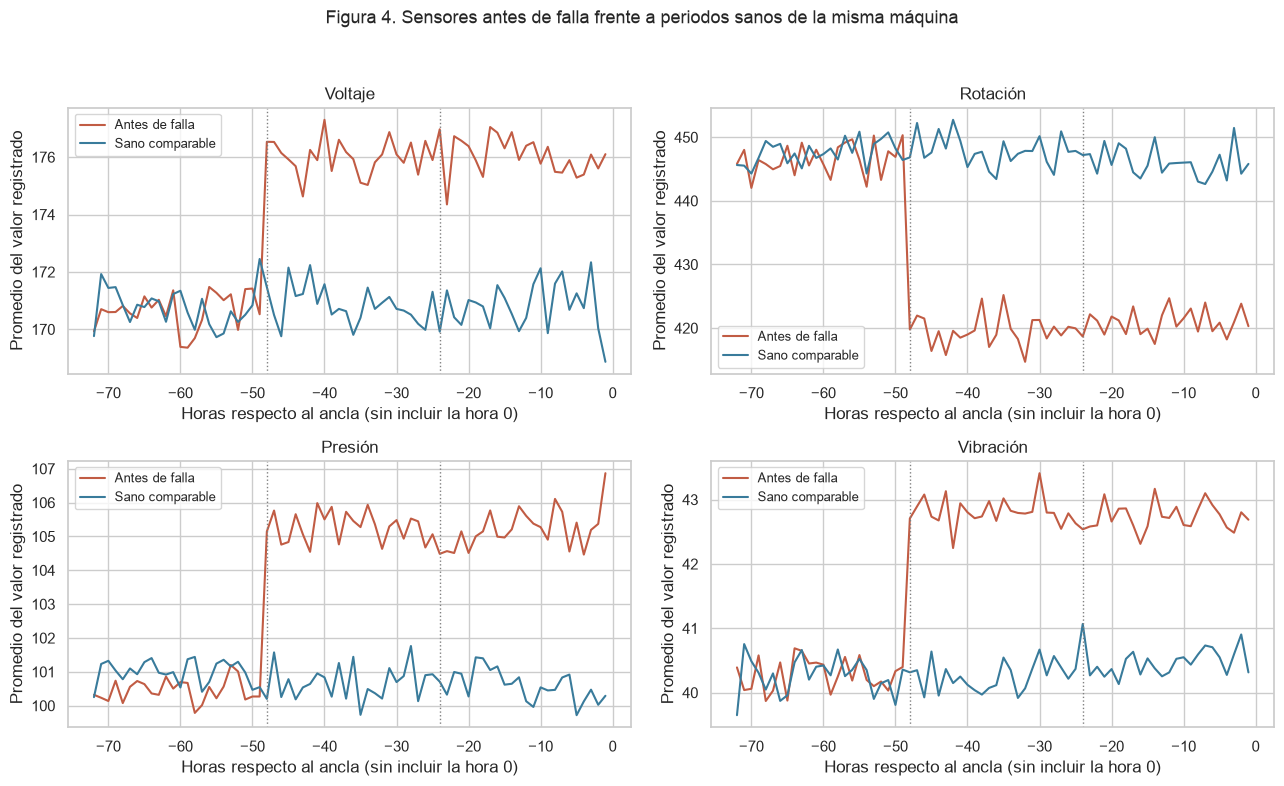

,ultimas_horas,sensor,promedio_antes_falla,promedio_sano,diferencia
0,72,volt,174.240,170.808,3.432
1,72,rotate,429.015,447.169,-18.154
2,72,pressure,103.649,100.756,2.893
3,72,vibration,41.942,40.333,1.610
4,48,volt,176.039,170.830,5.208
5,48,rotate,420.244,446.962,-26.719
6,48,pressure,105.246,100.639,4.606
7,48,vibration,42.772,40.366,2.406
8,24,volt,176.065,170.801,5.263
9,24,rotate,420.894,446.048,-25.154


In [7]:
# Promediar cada sensor por grupo y distancia al ancla, manteniendo la alineación de ventanas.
promedios_hora = ventanas.groupby(["grupo", "hora_relativa"])[sensores].mean()

# Crear varios paneles para comparar sin mezclar las escalas de los sensores.
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

# zip empareja cada sensor con un panel; flat recorre los paneles de la cuadrícula.
for sensor, eje in zip(sensores, ejes.flat):
    
    # Dibujar ambas condiciones con los mismos colores en todos los paneles.
    for grupo, color in [("Antes de falla", "#c15c44"), ("Sano comparable", "#397b9b")]:
        curva = promedios_hora.loc[grupo, sensor]
        eje.plot(curva.index, curva.values, label=grupo, color=color)
    
    # Añadir referencias de 48 y 24 horas para ubicar cuándo aparecen las diferencias.
    eje.axvline(-48, color="gray", linestyle=":", linewidth=1)
    eje.axvline(-24, color="gray", linestyle=":", linewidth=1)
    eje.set_title(nombres_sensores[sensor])
    eje.set_xlabel("Horas respecto al ancla (sin incluir la hora 0)")
    eje.set_ylabel("Promedio del valor registrado")
    eje.legend(fontsize=9)
fig.suptitle("Figura 4. Sensores antes de falla frente a periodos sanos de la misma máquina", fontsize=13)

# Ajustar los espacios para evitar que los títulos y etiquetas se encimen.
fig.tight_layout(rect=(0, 0, 1, 0.95))

# Guardar una copia de la figura; no modifica los datos originales.
fig.savefig(ruta_figuras / "04_trayectoria_72h.png", dpi=160, bbox_inches="tight")

# Mostrar la figura en la salida del notebook.
plt.show()

# Resumir ventanas completas y sus últimas 48 y 24 horas, en la escala original.
resumen_ventanas = []

# Repetir el resumen para la ventana completa y para sus últimos dos días y último día.
for horas in [72, 48, 24]:
    
    # Combinar condiciones con &: incluir enero y excluir septiembre y todo lo posterior.
    seleccion = ventanas[ventanas["hora_relativa"] >= -horas]
    tabla = seleccion.groupby("grupo")[sensores].mean()
    for sensor in sensores:
        
        # Extraer los promedios de ambos grupos antes de calcular su diferencia en la escala original.
        media_falla = tabla.loc["Antes de falla", sensor]
        media_sana = tabla.loc["Sano comparable", sensor]
        resumen_ventanas.append({"ultimas_horas": horas, "sensor": sensor,
                                 "promedio_antes_falla": media_falla,
                                 "promedio_sano": media_sana,
                                 "diferencia": media_falla - media_sana})
resumen_ventanas = pd.DataFrame(resumen_ventanas)
display(resumen_ventanas.round(3))

En el promedio de las ventanas aparece una separación clara alrededor de **48 horas antes de la falla**: aumentan voltaje, presión y vibración, mientras disminuye la rotación. Entre −72 y aproximadamente −49 horas, ambas curvas son más cercanas.

En las últimas **48 horas**, las diferencias frente al control son aproximadamente **+5.21 en voltaje, −26.72 en rotación, +4.61 en presión y +2.41 en vibración**, en la escala original de cada sensor. El promedio de 72 horas diluye esos cambios porque también incluye horas anteriores a la separación.

Este patrón hace razonable estudiar ventanas históricas y variables móviles en los siguientes pasos. Es un hallazgo de este conjunto simulado; no prueba que una alerta pueda detectar cada falla ni que vaya a comportarse igual en una planta real.

## 7. Separar el comportamiento por componente

Mezclar todos los componentes puede ocultar señales diferentes. Vamos a comparar cada ventana previa con **su propio control sano**, por sensor y componente.

Para facilitar la lectura, dividiremos la diferencia de cada par por la desviación estándar del sensor de esa máquina, calculada solo en entrenamiento. Un valor de 1 significa una diferencia de una desviación estándar; un valor negativo significa que el sensor está por debajo del control.

Esta escala se utiliza solo para describir la gráfica. **No es todavía la normalización del modelo** ni una decisión sobre qué variables conservar. No usaremos estadísticas de validación o prueba.

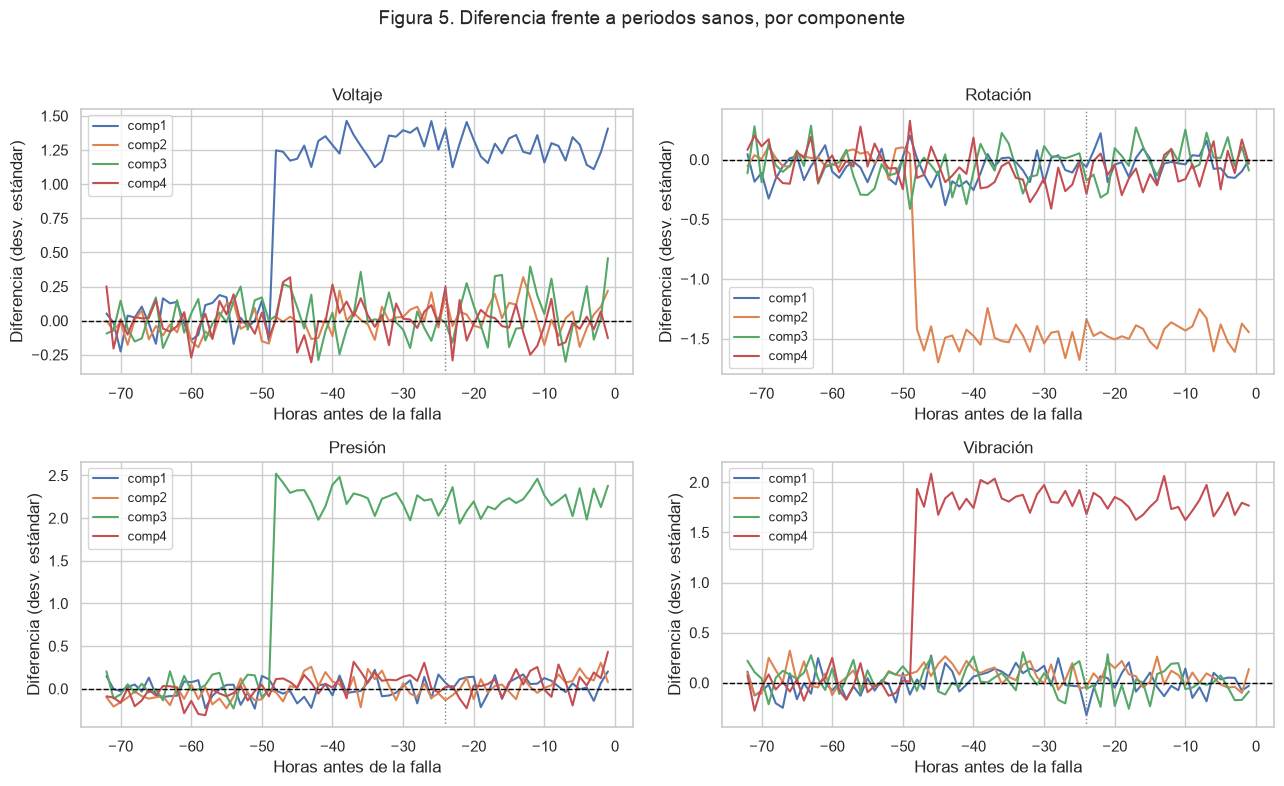

,volt,rotate,pressure,vibration
failure,,,,
comp1,1.268,-0.029,0.046,-0.017
comp2,0.047,-1.445,0.046,0.056
comp3,0.066,0.000,2.196,-0.029
comp4,-0.033,-0.087,0.068,1.779


In [8]:
# Calcular la variabilidad habitual de cada máquina usando solo sus datos de entrenamiento.
desviaciones = telemetria.groupby("machineID")[sensores].std()

# Evitar dividir entre cero si un sensor no presenta variación en una máquina.
assert (desviaciones > 0).all().all()

# Indexar por par y hora relativa asegura que cada dato se compare con su control correspondiente.
antes = ventanas[ventanas["grupo"] == "Antes de falla"].set_index(["par", "hora_relativa"])
sanas = ventanas[ventanas["grupo"] == "Sano comparable"].set_index(["par", "hora_relativa"])

# Restar valores alineados: antes de falla menos control sano, para cada sensor.
diferencias = antes[sensores] - sanas[sensores]
diferencias["machineID"] = antes["machineID"]
diferencias = diferencias.reset_index()

# Recorrer los sensores para mostrar cada resumen por separado.
for sensor in sensores:
    
    # map asigna a cada fila la desviación estándar del sensor de su máquina.
    escala = diferencias["machineID"].map(desviaciones[sensor])
    
    # Expresar la diferencia en desviaciones estándar; esta escala es solo descriptiva.
    diferencias[sensor] = diferencias[sensor] / escala

# Añadir el componente; una ventana con fallas simultáneas pertenece a varios componentes.
diferencias_componentes = diferencias.merge(
    pares_componentes[["par", "failure"]], on="par", how="inner", validate="many_to_many"
)
# Promediar las diferencias de cada componente a cada distancia de su falla.
curvas_componente = diferencias_componentes.groupby(["failure", "hora_relativa"])[sensores].mean()

# Crear varios paneles para comparar sin mezclar las escalas de los sensores.
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

# zip empareja cada sensor con un panel; flat recorre los paneles de la cuadrícula.
for sensor, eje in zip(sensores, ejes.flat):
    for componente in componentes:
        if componente in curvas_componente.index.get_level_values("failure"):
            curva = curvas_componente.loc[componente, sensor]
            eje.plot(curva.index, curva.values, label=componente)
            
    # Marcar cero: valores positivos están por encima del control y negativos por debajo.
    eje.axhline(0, color="black", linewidth=1, linestyle="--")
    eje.axvline(-24, color="gray", linestyle=":", linewidth=1)
    eje.set_title(nombres_sensores[sensor])
    eje.set_xlabel("Horas antes de la falla")
    eje.set_ylabel("Diferencia (desv. estándar)")
    eje.legend(fontsize=9)
fig.suptitle("Figura 5. Diferencia frente a periodos sanos, por componente", fontsize=14)

# Ajustar los espacios para evitar que los títulos y etiquetas se encimen.
fig.tight_layout(rect=(0, 0, 1, 0.95))

# Guardar una copia de la figura; no modifica los datos originales.
fig.savefig(ruta_figuras / "05_diferencias_por_componente.png", dpi=160, bbox_inches="tight")

# Mostrar la figura en la salida del notebook.
plt.show()

# Resumir las últimas 24 horas por componente, en el mismo orden que las curvas.
efectos_24h = diferencias_componentes[diferencias_componentes["hora_relativa"] >= -24].groupby("failure")[sensores].mean().reindex(componentes)
display(efectos_24h.round(3))

La separación por componente deja ver una asociación principal distinta en las últimas 24 horas:

| Componente | Cambio destacado frente al control sano |
|---|---|
| comp1 | Voltaje más alto: aproximadamente **+1.27 desviaciones estándar** |
| comp2 | Rotación más baja: aproximadamente **−1.45 desviaciones estándar** |
| comp3 | Presión más alta: aproximadamente **+2.20 desviaciones estándar** |
| comp4 | Vibración más alta: aproximadamente **+1.78 desviaciones estándar** |

Los demás cambios promedio son mucho menores en esta tabla. Estas asociaciones ayudan a interpretar las señales y plantean hipótesis para el modelado; **no son reglas de diagnóstico** ni justifican usar únicamente un sensor por componente. Las ventanas con fallas simultáneas y el carácter simulado de los datos también deben tenerse presentes.

## 8. Qué dejamos listo y qué sigue

Este notebook cubre la distribución de sensores por modelo, la frecuencia de eventos y la comparación de las 72 horas previas a fallas con periodos sanos comparables. Las cinco figuras quedan en `EDA/Figuras` y las tablas y explicaciones permanecen en el notebook.

**Límites de la comparación:** los datos son simulados; “sano” se define por ausencia de fallas registradas, no por una inspección física; los controles no necesariamente son del mismo mes; algunas ventanas se solapan; y una falla simultánea puede aparecer en más de un componente. Los promedios no garantizan que todas las fallas individuales presenten el mismo patrón. No estamos midiendo capacidad predictiva.

**Siguiente paso:** analizar la relación entre `PdM_maint` y `PdM_failures` antes de construir etiquetas y variables. Eso permitirá decidir qué información de reemplazos estaba disponible en cada hora y evitar usar consecuencias de una falla como señales previas.